In [1]:
import tensorflow as tf
from datasets import load_dataset
import numpy as np
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dropout,
    Dense
)
import time

X_train: (50000, 32, 32, 3)
y_train: (50000,)
X_test: (10000, 32, 32, 3)
y_test: (10000,)
classes: [0 1 2 3 4 5 6 7 8 9]


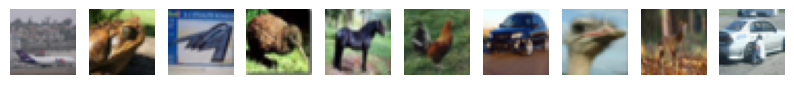

In [2]:
ds = load_dataset("uoft-cs/cifar10")

X_train = np.asarray(ds["train"].with_format("numpy")["img"])
y_train = np.asarray(ds["train"]["label"])

X_test = np.asarray(ds["test"].with_format("numpy")["img"])
y_test = np.asarray(ds["test"]["label"])

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("classes:", np.unique(y_test))

plt.figure(figsize=(10, 2))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i])
    plt.axis("off")

plt.show()

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 64

def preprocess_image(image, label):
    image = tf.cast(image, tf.float32) # Converter le type à float32
    image = tf.image.resize(image, IMG_SIZE) # resase les image
    image = preprocess_input(image) # Normalization adapter pour MobileNetV2 ente 1 et -1
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(1000)
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_ds = (
    test_ds
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


for images, labels in train_ds.take(1):
    print("Images shape :", images.shape)
    print("Labels shape :", labels.shape)
    print("Min pixel :", tf.reduce_min(images).numpy())
    print("Max pixel :", tf.reduce_max(images).numpy())

I0000 00:00:1792522089.395318     400 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792522089.397472     400 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Images shape : (64, 224, 224, 3)
Labels shape : (64,)
Min pixel : -1.0
Max pixel : 1.0


In [4]:
base_model = MobileNetV2(
    weights="imagenet", # loader les whites from imagesnet
    include_top=False, # remove clases of imagesnet
    input_shape=(224, 224, 3) # size input of images
)

base_model.trainable = False # frozen all layers of model base (Freezing)

base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model = Sequential([
    base_model, # mobel net v2
    GlobalAveragePooling2D(), # converter Feature map à vectore
    Dropout(0.2), # éviter overffeting
    Dense(10, activation="softmax") # output layer
])


model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

training_time = time.time() - start_time

print(f"Temps d'entraînement : {training_time:.2f} secondes")

Epoch 1/5


2026-10-20 18:48:28.182310: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 18:48:28.321339: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792522110.613833     448 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6747 - loss: 0.9659

2026-10-20 18:49:15.950205: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 18:49:16.093667: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-20 18:49:16.230025: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


782/782 ━━━━━━━━━━━━━━━━━━━━ 80s 80ms/step - accuracy: 0.7678 - loss: 0.6783 - val_accuracy: 0.8358 - val_loss: 0.4792
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 46s 58ms/step - accuracy: 0.8312 - loss: 0.4904 - val_accuracy: 0.8430 - val_loss: 0.4531
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 58ms/step - accuracy: 0.8376 - loss: 0.4663 - val_accuracy: 0.8384 - val_loss: 0.4691
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 46s 58ms/step - accuracy: 0.8429 - loss: 0.4518 - val_accuracy: 0.8477 - val_loss: 0.4517
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 58ms/step - accuracy: 0.8465 - loss: 0.4446 - val_accuracy: 0.8508 - val_loss: 0.4409
Temps d'entraînement : 261.70 secondes


In [12]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False
    
    
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 90s 95ms/step - accuracy: 0.8132 - loss: 0.5555 - val_accuracy: 0.8580 - val_loss: 0.4319
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 59s 76ms/step - accuracy: 0.8637 - loss: 0.4014 - val_accuracy: 0.8719 - val_loss: 0.3948
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 58s 74ms/step - accuracy: 0.8829 - loss: 0.3328 - val_accuracy: 0.8796 - val_loss: 0.3661
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 58s 74ms/step - accuracy: 0.9024 - loss: 0.2841 - val_accuracy: 0.8856 - val_loss: 0.3453
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 58s 74ms/step - accuracy: 0.9113 - loss: 0.2550 - val_accuracy: 0.8906 - val_loss: 0.3324


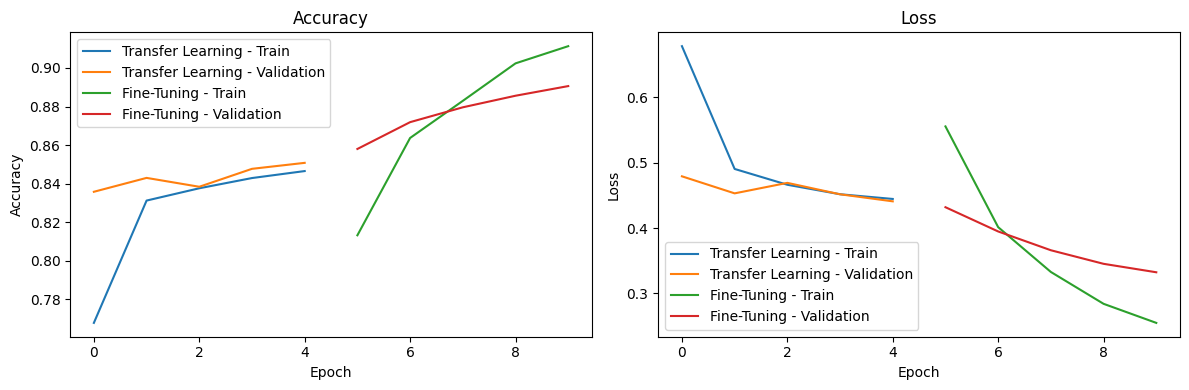

In [13]:
# Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Transfer Learning - Train")
plt.plot(history.history["val_accuracy"], label="Transfer Learning - Validation")
plt.plot(
    range(len(history.history["accuracy"]),
          len(history.history["accuracy"]) + len(history_fine.history["accuracy"])),
    history_fine.history["accuracy"],
    label="Fine-Tuning - Train"
)
plt.plot(
    range(len(history.history["val_accuracy"]),
          len(history.history["val_accuracy"]) + len(history_fine.history["val_accuracy"])),
    history_fine.history["val_accuracy"],
    label="Fine-Tuning - Validation"
)

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Transfer Learning - Train")
plt.plot(history.history["val_loss"], label="Transfer Learning - Validation")
plt.plot(
    range(len(history.history["loss"]),
          len(history.history["loss"]) + len(history_fine.history["loss"])),
    history_fine.history["loss"],
    label="Fine-Tuning - Train"
)
plt.plot(
    range(len(history.history["val_loss"]),
          len(history.history["val_loss"]) + len(history_fine.history["val_loss"])),
    history_fine.history["val_loss"],
    label="Fine-Tuning - Validation"
)

plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()